In [105]:
import os

import pandas


RESULT_PATH_PREFIX = 'sample_aris_df_threshold_ds'


results_csv_paths = [
    subpath
    for subpath in os.listdir()
    if subpath.startswith(RESULT_PATH_PREFIX)
]

results_csvs = [
    pandas.read_csv(subpath)
    for subpath in results_csv_paths
]

In [106]:
for path, csv in zip(results_csv_paths, results_csvs):
    threshold = path.split('_')[5]
    run = path.split('_')[-1].split('.')[0]
    csv['threshold'] = float(threshold)
    csv['run'] = int(run)

In [107]:
full_result_csv = pandas.concat(results_csvs, ignore_index=True)

In [108]:
full_result_csv.columns

Index(['151673', '151672', '151507', '151508', '151669', '151509', '151671',
       '151510', '151670', '151674', '151675', '151676',
       'nb_of_standard_components', 'threshold', 'run'],
      dtype='object')

In [109]:
FULL_SAMPLE_COLS = ['151673', '151672', '151507', '151508', '151669', '151509', '151671',
       '151510', '151670', '151674', '151675', '151676']

In [110]:
full_result_csv.shape

(900, 15)

In [111]:
#full_result_csv = full_result_csv.groupby(['threshold', 'run'])[FULL_SAMPLE_COLS].max().reset_index()

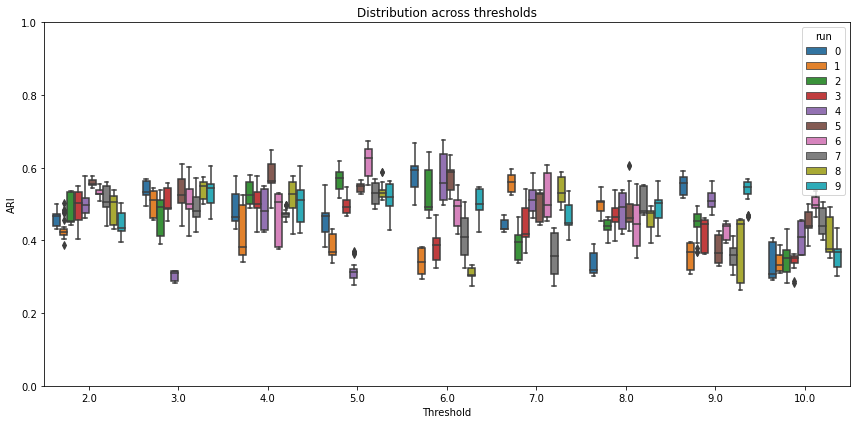

In [112]:
import matplotlib.pyplot as plt
import seaborn as sns


TEST_SAMPLES = [
    '151507',
    '151672',
    '151673',
]


df_long = full_result_csv.melt(
    id_vars=["threshold", 'run'],
    value_vars=TEST_SAMPLES,
    var_name="sample",
    value_name="value"
)


df_long = df_long.sort_values('threshold')


# plot
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_long, x="threshold", y="value", hue='run')

plt.title("Distribution across thresholds")
plt.xlabel("Threshold")
plt.ylabel("ARI")
plt.ylim([0, 1])

plt.tight_layout()
plt.show()

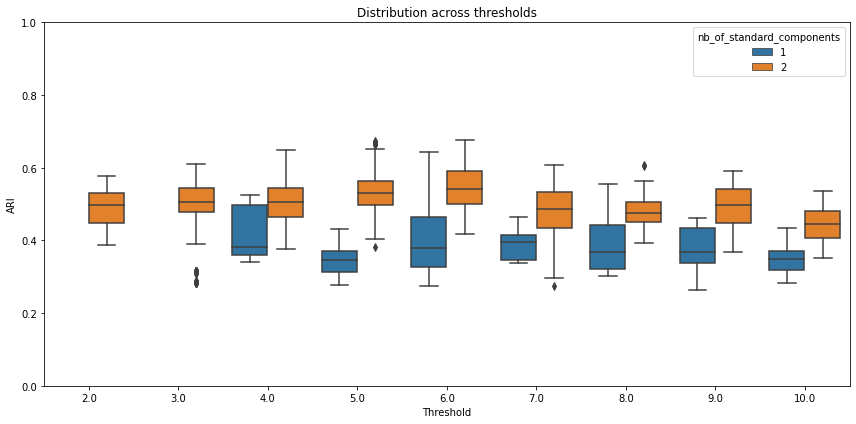

In [113]:
import matplotlib.pyplot as plt
import seaborn as sns


TEST_SAMPLES = [
    '151507',
    '151672',
    '151673',
]


df_long = full_result_csv.melt(
    id_vars=["threshold", 'nb_of_standard_components'],
    value_vars=TEST_SAMPLES,
    var_name="sample",
    value_name="value"
)


df_long = df_long.sort_values('threshold')


# plot
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_long, x="threshold", y="value", hue='nb_of_standard_components')

plt.title("Distribution across thresholds")
plt.xlabel("Threshold")
plt.ylabel("ARI")
plt.ylim([0, 1])

plt.tight_layout()
plt.show()

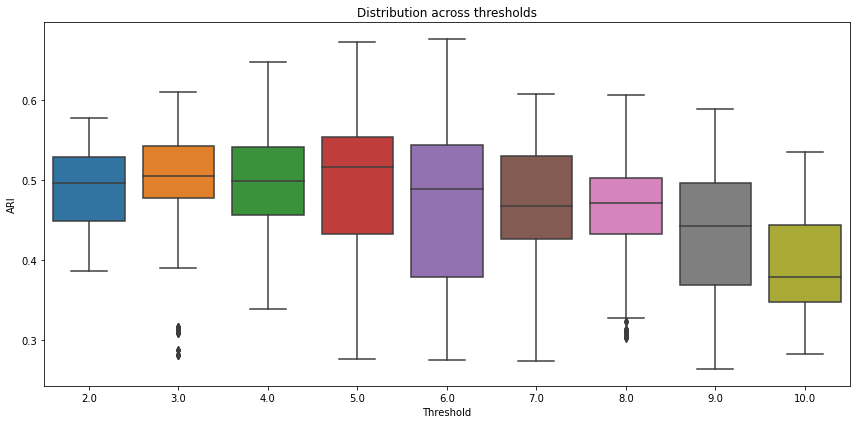

In [114]:
TEST_SAMPLES = [
    '151507',
    '151672',
    '151673',
]

current_results = full_result_csv 
df_long = current_results.melt(
    id_vars=["threshold"],
    value_vars=TEST_SAMPLES,
    var_name="sample",
    value_name="value"
)


df_long = df_long.sort_values('threshold')


# plot
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_long, x="threshold", y="value")

plt.title(f"Distribution across thresholds")
plt.xlabel("Threshold")
plt.ylabel("ARI")

plt.tight_layout()
plt.show()

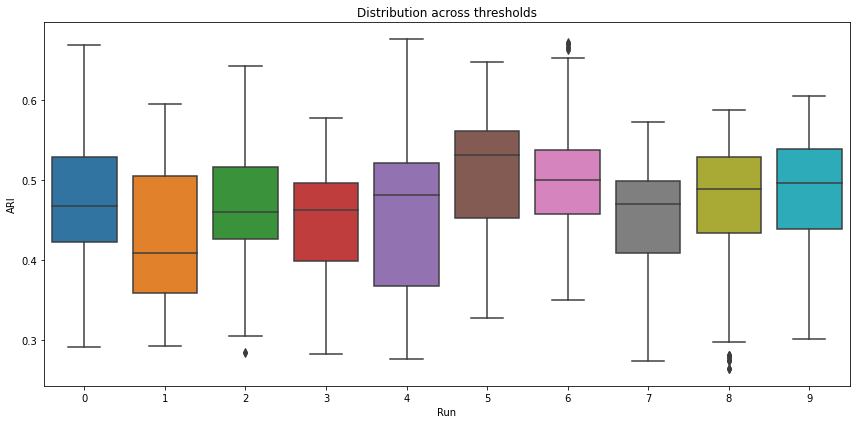

In [115]:
TEST_SAMPLES = [
    '151507',
    '151672',
    '151673',
]

current_results = full_result_csv 
df_long = current_results.melt(
    id_vars=["run"],
    value_vars=TEST_SAMPLES,
    var_name="sample",
    value_name="value"
)


df_long = df_long.sort_values('run')


# plot
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_long, x="run", y="value")

plt.title(f"Distribution across thresholds")
plt.xlabel("Run")
plt.ylabel("ARI")

plt.tight_layout()
plt.show()

In [70]:
NON_TEST_SAMPLES = [sample for sample in FULL_SAMPLE_COLS if sample not in TEST_SAMPLES]

In [71]:
df_long_run_train = current_results.groupby(['run', 'threshold'])[NON_TEST_SAMPLES].mean().mean(axis=1).to_frame().reset_index()
df_long_run_test = current_results.groupby(['run', 'threshold'])[TEST_SAMPLES].mean().mean(axis=1).to_frame().reset_index()

In [72]:
df_long_run_train

,run,threshold,0
0,0,2.0,0.404028
1,0,3.0,0.471672
2,0,4.0,0.383249
3,0,5.0,0.374034
4,0,6.0,0.497833
...,...,...,...
85,9,6.0,0.454835
86,9,7.0,0.365967
87,9,8.0,0.451474
88,9,9.0,0.443708


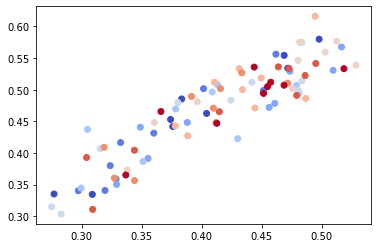

In [78]:
plt.scatter(
    df_long_run_train[0], df_long_run_test[0], c=df_long_run_train['run'], cmap='coolwarm')

In [79]:
model_prefix = 'DLPFC_CELLOHOOD_MODEL_GPU'


model_paths = [
    path 
    for path in os.listdir()
    if path.startswith(model_prefix)
]

In [80]:
histories = []


for path in model_paths:
    threshold = float(path.split('_')[4])
    run = int(path.split('_')[5])
    history_path = os.path.join(path, 'model_history.df')
    history = pandas.read_csv(history_path)
    history['threshold'] = threshold
    history['run'] = run
    histories.append(history)

In [81]:
histories_df = pandas.concat(histories, ignore_index=True)

In [82]:
histories_df_last = histories_df[histories_df['Unnamed: 0'] == 99]

(array([ 9.,  4.,  7., 11., 18., 11.,  8.,  0., 12., 10.]),
 array([0.02404674, 0.05207788, 0.08010901, 0.10814015, 0.13617129,
        0.16420242, 0.19223356, 0.22026469, 0.24829583, 0.27632696,
        0.3043581 ]),
 <BarContainer object of 10 artists>)

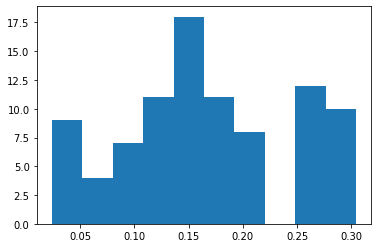

In [83]:
plt.hist(histories_df_last['loss'])

In [84]:
histories_df_last = histories_df_last.sort_values(['threshold', 'run'])

In [85]:
#df_long = df_long.sort_values(['threshold', 'run'])

In [86]:
histories_df_last.shape

(90, 5)

In [87]:
grouped_results = full_result_csv.groupby(['threshold', 'run'])[TEST_SAMPLES].mean().reset_index()

In [88]:
total_with_loss = pandas.merge(grouped_results, histories_df_last)

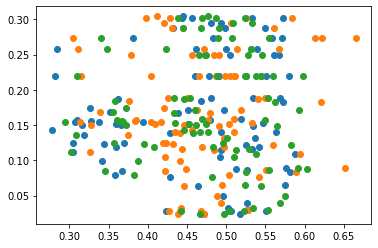

In [89]:
for sample in TEST_SAMPLES:
    plt.scatter(total_with_loss[sample], total_with_loss['loss'])

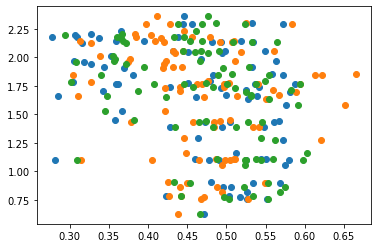

In [90]:
for sample in TEST_SAMPLES:
    plt.scatter(total_with_loss[sample], total_with_loss['ent'])

In [91]:
!cat /raid/immucan/immuw/cellohood-analyses/analyses/DLPFC_ABLATION/DLPFC_CELLOHOOD_MODEL_10.0/model_class.txt

BaseWinterCellEnvironmentAEV2

In [92]:
total_with_loss

,threshold,run,151507,151672,151673,Unnamed: 0,loss,ent
0,2.0,0,0.471167,0.438559,0.466584,99,0.024271,0.626367
1,2.0,1,0.423284,0.426978,0.442069,99,0.028669,0.787300
2,2.0,2,0.534589,0.449360,0.454206,99,0.188183,0.900409
3,2.0,3,0.502859,0.442752,0.533926,99,0.032186,0.782776
4,2.0,4,0.517901,0.471352,0.497054,99,0.024047,0.772788
...,...,...,...,...,...,...,...,...
85,10.0,5,0.438738,0.479373,0.433049,99,0.167636,2.176859
86,10.0,6,0.519203,0.509334,0.468948,99,0.158148,2.139803
87,10.0,7,0.445394,0.411090,0.476513,99,0.304358,2.360856
88,10.0,8,0.467768,0.376615,0.357880,99,0.184013,1.986878


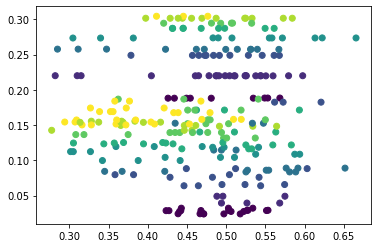

In [93]:
for sample in TEST_SAMPLES:
    plt.scatter(total_with_loss[sample], total_with_loss['loss'], c=total_with_loss['threshold'])

In [118]:
!ls /raid/immucan/immuw/cellohood-analyses/analyses/DLPFC_ABLATION/DLPFC_CELLOHOOD_MODEL_10.0/

ctr.json    model_class.txt   model_weights.h5	training_params.json
model.json  model_history.df  scaler.joblib


In [119]:
!/raid/immucan/immuw/cellohood-analyses/analyses/DLPFC_ABLATION/DLPFC_CELLOHOOD_MODEL_10.0/model_class.txt

/bin/bash: /raid/immucan/immuw/cellohood-analyses/analyses/DLPFC_ABLATION/DLPFC_CELLOHOOD_MODEL_10.0/model_class.txt: Permission denied
